# 🚌 Klagenfurt Shuttle Fleet Simulation

## Realistische Shuttle-Service Analyse für verschiedene Flottengrößen

Diese Simulation testet die Performance von Shuttle-Flotten unterschiedlicher Größen (8, 16, 24, 32 Fahrzeuge) unter realistischen Nachfragebedingungen in Klagenfurt.

**Zielsetzung:**
- Analyse von zwei täglichen Spitzenzeiten (Morgen- und Nachmittagsverkehr)
- Bewertung der Service-Qualität verschiedener Flottengrößen
- Entwicklung von Empfehlungen für optimale Flottengröße

**Simulation basiert auf:**
- 🏫 **Morgen-Spitze (07:00-09:00)**: Schulverkehr und Pendler
- 🏢 **Nachmittag-Spitze (15:00-18:00)**: Berufsverkehr und Heimfahrten
- 🕐 **Nebenstunden**: Normaler Stadtverkehr

In [ ]:
# Import required libraries for shuttle fleet simulation
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Set up plotting style for professional visualizations
plt.style.use('default')
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8
plt.rcParams['axes.grid'] = True
sns.set_style("whitegrid")

# Set up results directory for saving outputs
results_dir = os.path.join(os.path.dirname(os.getcwd()), "results")
os.makedirs(results_dir, exist_ok=True)
print(f"📁 Results will be saved to: {results_dir}")

# Initialize random seed for reproducible results
np.random.seed(42)
print("✅ Libraries imported and environment configured")

## 1. Realistische Nachfrage-Generierung

Wir generieren 500 realistische Fahrtanfragen basierend auf typischen Verkehrsmustern einer österreichischen Stadt:

- **? Morgen-Spitze (07:00-09:00)**: 40% der Anfragen - Schulverkehr und Pendler
- **? Nachmittag-Spitze (15:00-18:00)**: 35% der Anfragen - Berufsverkehr und Rückfahrten  
- **🕐 Nebenstunden**: 25% der Anfragen - Normaler Stadtverkehr

In [49]:
# 🚌 SHUTTLE-FLOTTEN SIMULATION: Realistische Nachfrage mit zwei Spitzenzeiten
print("="*80)
print("🚌 KLAGENFURT SHUTTLE-SERVICE SIMULATION")
print("="*80)

# Generiere realistische Nachfrage für einen ganzen Tag mit zwei Spitzenzeiten
def generate_realistic_demand(num_requests=500, random_seed=42):
    """
    Generiert realistische Nachfrage für Klagenfurt mit zwei Spitzenzeiten:
    - Morgens: 07:00-09:00 (Schulverkehr + Pendler)
    - Nachmittags: 15:00-18:00 (Berufsverkehr + Schule)
    """
    np.random.seed(random_seed)

    # Zeitverteilung für einen Tag (in Sekunden ab Mitternacht)
    # 07:00 = 7*3600 = 25200 Sekunden
    # 09:00 = 9*3600 = 32400 Sekunden
    # 15:00 = 15*3600 = 54000 Sekunden
    # 18:00 = 18*3600 = 64800 Sekunden

    requests = []
    request_id = 0

    # Klagenfurt Zonengrenzen (ungefähr, für Simulation)
    # Verwende einfache ID-Bereiche für Start/Ziel-Punkte
    zone_ids = list(range(1, 201))  # 200 verschiedene Punkte in Klagenfurt

    # MORGEN-SPITZE: 07:00-09:00 (40% der Tagesanfragen)
    morning_requests = int(num_requests * 0.40)
    print(f"🌅 Generiere {morning_requests} Morgen-Anfragen (07:00-09:00)...")

    for _ in range(morning_requests):
        # Normalverteilung um 08:00 Uhr mit 30min Standardabweichung
        time_offset = np.random.normal(0, 1800)  # 30min = 1800 sec
        rq_time = 8 * 3600 + time_offset  # 08:00 + offset
        rq_time = max(7 * 3600, min(9 * 3600, rq_time))  # Begrenze auf 07:00-09:00

        start = np.random.choice(zone_ids)
        end = np.random.choice([z for z in zone_ids if z != start])

        requests.append({
            'request_id': request_id,
            'rq_time': rq_time,
            'start': start,
            'end': end,
            'earliest_pickup_time': rq_time,
            'peak_type': 'morning'
        })
        request_id += 1

    # NACHMITTAG-SPITZE: 15:00-18:00 (35% der Tagesanfragen)
    afternoon_requests = int(num_requests * 0.35)
    print(f"🌆 Generiere {afternoon_requests} Nachmittag-Anfragen (15:00-18:00)...")

    for _ in range(afternoon_requests):
        # Normalverteilung um 16:30 Uhr mit 45min Standardabweichung
        time_offset = np.random.normal(0, 2700)  # 45min = 2700 sec
        rq_time = 16.5 * 3600 + time_offset  # 16:30 + offset
        rq_time = max(15 * 3600, min(18 * 3600, rq_time))  # Begrenze auf 15:00-18:00

        start = np.random.choice(zone_ids)
        end = np.random.choice([z for z in zone_ids if z != start])

        requests.append({
            'request_id': request_id,
            'rq_time': rq_time,
            'start': start,
            'end': end,
            'earliest_pickup_time': rq_time,
            'peak_type': 'afternoon'
        })
        request_id += 1

    # NEBENSTUNDEN: Rest des Tages (25% der Tagesanfragen)
    off_peak_requests = num_requests - morning_requests - afternoon_requests
    print(f"🕐 Generiere {off_peak_requests} Nebenstunden-Anfragen...")

    # Verteile über den Rest des Tages: 09:00-15:00 und 18:00-22:00
    off_peak_times = []
    # 09:00-15:00 (6 Stunden)
    for hour in range(9, 15):
        off_peak_times.extend([hour * 3600 + np.random.randint(0, 3600) for _ in range(20)])
    # 18:00-22:00 (4 Stunden)
    for hour in range(18, 22):
        off_peak_times.extend([hour * 3600 + np.random.randint(0, 3600) for _ in range(15)])

    # Zufällige Auswahl der Zeiten
    selected_times = np.random.choice(off_peak_times, off_peak_requests, replace=False)

    for rq_time in selected_times:
        start = np.random.choice(zone_ids)
        end = np.random.choice([z for z in zone_ids if z != start])

        requests.append({
            'request_id': request_id,
            'rq_time': float(rq_time),
            'start': start,
            'end': end,
            'earliest_pickup_time': float(rq_time),
            'peak_type': 'off_peak'
        })
        request_id += 1

    # Sortiere nach Zeit
    requests.sort(key=lambda x: x['rq_time'])

    # Aktualisiere request_ids nach Sortierung
    for i, req in enumerate(requests):
        req['request_id'] = i

    return pd.DataFrame(requests)

# Generiere realistische Nachfrage
realistic_demand = generate_realistic_demand(num_requests=500)

print(f"\n📊 NACHFRAGE-ÜBERSICHT:")
print(f"Gesamt-Anfragen: {len(realistic_demand)}")
print(f"Zeitspanne: {realistic_demand['rq_time'].min()/3600:.1f}h bis {realistic_demand['rq_time'].max()/3600:.1f}h")

# Analyse der Spitzenzeiten
peak_analysis = realistic_demand.groupby('peak_type').agg({
    'request_id': 'count',
    'rq_time': ['min', 'max']
}).round(1)

print(f"\n🕐 SPITZENZEITEN-VERTEILUNG:")
for peak_type in ['morning', 'afternoon', 'off_peak']:
    subset = realistic_demand[realistic_demand['peak_type'] == peak_type]
    if len(subset) > 0:
        count = len(subset)
        min_time = subset['rq_time'].min() / 3600
        max_time = subset['rq_time'].max() / 3600
        percentage = (count / len(realistic_demand)) * 100

        peak_names = {
            'morning': '🌅 Morgen-Spitze',
            'afternoon': '🌆 Nachmittag-Spitze',
            'off_peak': '🕐 Nebenstunden'
        }

        print(f"{peak_names[peak_type]}: {count} Anfragen ({percentage:.1f}%) - {min_time:.1f}h bis {max_time:.1f}h")

# Stündliche Verteilung
realistic_demand['hour'] = (realistic_demand['rq_time'] / 3600).astype(int)
hourly_distribution = realistic_demand['hour'].value_counts().sort_index()

print(f"\n📈 STÜNDLICHE VERTEILUNG:")
for hour, count in hourly_distribution.items():
    percentage = (count / len(realistic_demand)) * 100
    bar = "█" * int(count / 10) if count >= 10 else "▓" if count >= 5 else "░"
    print(f"{hour:02d}:00 - {count:3d} Anfragen ({percentage:4.1f}%) {bar}")

print(f"\n✅ Realistische Nachfrage erfolgreich generiert!")
print("="*80)

🚌 KLAGENFURT SHUTTLE-SERVICE SIMULATION
🌅 Generiere 200 Morgen-Anfragen (07:00-09:00)...
🌆 Generiere 175 Nachmittag-Anfragen (15:00-18:00)...
🕐 Generiere 125 Nebenstunden-Anfragen...

📊 NACHFRAGE-ÜBERSICHT:
Gesamt-Anfragen: 500
Zeitspanne: 7.0h bis 21.9h

🕐 SPITZENZEITEN-VERTEILUNG:
🌅 Morgen-Spitze: 200 Anfragen (40.0%) - 7.0h bis 9.0h
🌆 Nachmittag-Spitze: 175 Anfragen (35.0%) - 15.0h bis 18.0h
🕐 Nebenstunden: 125 Anfragen (25.0%) - 9.0h bis 21.9h

📈 STÜNDLICHE VERTEILUNG:
07:00 - 107 Anfragen (21.4%) ██████████
08:00 -  88 Anfragen (17.6%) ████████
09:00 -  17 Anfragen ( 3.4%) █
10:00 -  18 Anfragen ( 3.6%) █
11:00 -  13 Anfragen ( 2.6%) █
12:00 -  11 Anfragen ( 2.2%) █
13:00 -  16 Anfragen ( 3.2%) █
14:00 -  15 Anfragen ( 3.0%) █
15:00 -  38 Anfragen ( 7.6%) ███
16:00 -  84 Anfragen (16.8%) ████████
17:00 -  48 Anfragen ( 9.6%) ████
18:00 -  16 Anfragen ( 3.2%) █
19:00 -  10 Anfragen ( 2.0%) █
20:00 -   9 Anfragen ( 1.8%) ▓
21:00 -  10 Anfragen ( 2.0%) █

✅ Realistische Nachfrage erf

In [50]:
# 🚌 SHUTTLE-FLOTTEN SIMULATOR
class ShuttleFleetSimulator:
    """
    Simuliert verschiedene Shuttle-Flottengrößen für Klagenfurt
    Testet: 8, 16, 24, 32 Fahrzeuge unter realistischen Bedingungen
    """

    def __init__(self, demand_data):
        self.demand_data = demand_data
        self.fleet_sizes = [8, 16, 24, 32]
        self.results = {}

        # Shuttle-Parameter (realistische Werte für Österreich)
        self.shuttle_capacity = 8  # 8 Passagiere pro Shuttle
        self.average_trip_time = 12  # 12 Minuten durchschnittliche Fahrzeit
        self.pickup_time = 2  # 2 Minuten für Ein-/Ausstieg
        self.repositioning_time = 5  # 5 Minuten zwischen den Fahrten

    def simulate_fleet_performance(self, fleet_size, verbose=False):
        """
        Simuliert die Performance einer bestimmten Flottengröße
        """
        if verbose:
            print(f"\n🚌 Simuliere Flotte mit {fleet_size} Shuttles...")

        # Initialisiere Shuttles
        shuttles = []
        for i in range(fleet_size):
            shuttles.append({
                'id': i,
                'available_at': 0,  # Verfügbar ab Sekunde 0
                'current_location': np.random.randint(1, 201),  # Zufällige Startposition
                'trips_completed': 0,
                'total_passengers': 0,
                'total_drive_time': 0
            })

        served_requests = []
        rejected_requests = []

        # Verarbeite jede Anfrage
        for _, request in self.demand_data.iterrows():
            request_time = request['rq_time']

            # Finde verfügbares Shuttle
            available_shuttles = [s for s in shuttles if s['available_at'] <= request_time]

            if available_shuttles:
                # Wähle das Shuttle, das am längsten verfügbar ist
                chosen_shuttle = min(available_shuttles, key=lambda x: x['available_at'])

                # Berechne Fahrzeiten
                pickup_delay = max(0, request_time - chosen_shuttle['available_at'])
                travel_time = self.average_trip_time * 60  # Umwandlung in Sekunden
                total_service_time = pickup_delay + self.pickup_time * 60 + travel_time + self.pickup_time * 60

                # Aktualisiere Shuttle-Status
                chosen_shuttle['available_at'] = request_time + total_service_time + self.repositioning_time * 60
                chosen_shuttle['current_location'] = request['end']
                chosen_shuttle['trips_completed'] += 1
                chosen_shuttle['total_passengers'] += 1  # Annahme: 1 Passagier pro Anfrage
                chosen_shuttle['total_drive_time'] += travel_time

                # Speichere bediente Anfrage
                served_requests.append({
                    'request_id': request['request_id'],
                    'shuttle_id': chosen_shuttle['id'],
                    'pickup_time': request_time + pickup_delay,
                    'dropoff_time': request_time + total_service_time - self.pickup_time * 60,
                    'waiting_time': pickup_delay,
                    'travel_time': travel_time,
                    'peak_type': request['peak_type']
                })
            else:
                # Alle Shuttles sind beschäftigt
                rejected_requests.append({
                    'request_id': request['request_id'],
                    'request_time': request_time,
                    'peak_type': request['peak_type'],
                    'reason': 'no_available_shuttle'
                })

        # Berechne Leistungsmetriken
        total_requests = len(self.demand_data)
        served_count = len(served_requests)
        rejected_count = len(rejected_requests)
        service_rate = (served_count / total_requests) * 100

        if served_requests:
            avg_waiting_time = np.mean([r['waiting_time'] for r in served_requests]) / 60  # in Minuten
            max_waiting_time = max([r['waiting_time'] for r in served_requests]) / 60
            service_rate_10min = sum(1 for r in served_requests if r['waiting_time'] <= 600) / served_count * 100
        else:
            avg_waiting_time = float('inf')
            max_waiting_time = float('inf')
            service_rate_10min = 0

        # Flotten-Utilization
        total_trips = sum([s['trips_completed'] for s in shuttles])
        total_passengers = sum([s['total_passengers'] for s in shuttles])
        avg_trips_per_shuttle = total_trips / fleet_size

        # Spitzenzeiten-Analyse
        peak_analysis = {}
        for peak_type in ['morning', 'afternoon', 'off_peak']:
            peak_served = [r for r in served_requests if r['peak_type'] == peak_type]
            peak_total = len(self.demand_data[self.demand_data['peak_type'] == peak_type])
            peak_service_rate = (len(peak_served) / peak_total * 100) if peak_total > 0 else 0

            peak_analysis[peak_type] = {
                'total_requests': peak_total,
                'served_requests': len(peak_served),
                'service_rate': peak_service_rate,
                'avg_waiting_time': np.mean([r['waiting_time'] for r in peak_served]) / 60 if peak_served else 0
            }

        return {
            'fleet_size': fleet_size,
            'total_requests': total_requests,
            'served_requests': served_count,
            'rejected_requests': rejected_count,
            'service_rate': service_rate,
            'avg_waiting_time': avg_waiting_time,
            'max_waiting_time': max_waiting_time,
            'service_rate_10min': service_rate_10min,
            'total_trips': total_trips,
            'total_passengers': total_passengers,
            'avg_trips_per_shuttle': avg_trips_per_shuttle,
            'peak_analysis': peak_analysis,
            'shuttles_final_state': shuttles
        }

    def run_all_scenarios(self):
        """
        Führt Simulation für alle Flottengrößen durch
        """
        print(f"\n🚀 STARTE SHUTTLE-FLOTTEN SIMULATION")
        print(f"Teste Flottengrößen: {self.fleet_sizes}")
        print("-" * 60)

        for fleet_size in self.fleet_sizes:
            result = self.simulate_fleet_performance(fleet_size, verbose=True)
            self.results[fleet_size] = result

            print(f"   ✅ {result['served_requests']}/{result['total_requests']} Anfragen bedient ({result['service_rate']:.1f}%)")
            print(f"   ⏱️  Durchschnittliche Wartezeit: {result['avg_waiting_time']:.1f} Minuten")

        print("-" * 60)
        print("✅ Alle Simulationen abgeschlossen!")

        return self.results

# Führe Shuttle-Simulation durch
print("🚀 INITIALISIERE SHUTTLE-FLOTTEN SIMULATOR...")
shuttle_sim = ShuttleFleetSimulator(realistic_demand)
shuttle_results = shuttle_sim.run_all_scenarios()

# Erstelle Ergebnis-DataFrame für bessere Übersicht
results_data = []
for fleet_size, result in shuttle_results.items():
    results_data.append({
        'Flottengröße': fleet_size,
        'Bediente Anfragen': result['served_requests'],
        'Service Rate (%)': round(result['service_rate'], 1),
        'Ø Wartezeit (min)': round(result['avg_waiting_time'], 1),
        'Max Wartezeit (min)': round(result['max_waiting_time'], 1),
        'Service Rate ≤10min (%)': round(result['service_rate_10min'], 1),
        'Gesamte Fahrten': result['total_trips'],
        'Ø Fahrten pro Shuttle': round(result['avg_trips_per_shuttle'], 1)
    })

results_df = pd.DataFrame(results_data)

print(f"\n📊 SHUTTLE-FLOTTEN VERGLEICH:")
print("=" * 80)
display(results_df)

# Speichere Ergebnisse
results_df.to_csv(os.path.join(results_dir, "shuttle_fleet_comparison.csv"), index=False)
print(f"\n💾 Ergebnisse gespeichert in: {os.path.join(results_dir, 'shuttle_fleet_comparison.csv')}")
print("=" * 80)

🚀 INITIALISIERE SHUTTLE-FLOTTEN SIMULATOR...

🚀 STARTE SHUTTLE-FLOTTEN SIMULATION
Teste Flottengrößen: [8, 16, 24, 32]
------------------------------------------------------------

🚌 Simuliere Flotte mit 8 Shuttles...
   ✅ 105/500 Anfragen bedient (21.0%)
   ⏱️  Durchschnittliche Wartezeit: 39.9 Minuten

🚌 Simuliere Flotte mit 16 Shuttles...
   ✅ 165/500 Anfragen bedient (33.0%)
   ⏱️  Durchschnittliche Wartezeit: 52.9 Minuten

🚌 Simuliere Flotte mit 24 Shuttles...
   ✅ 207/500 Anfragen bedient (41.4%)
   ⏱️  Durchschnittliche Wartezeit: 67.4 Minuten

🚌 Simuliere Flotte mit 32 Shuttles...
   ✅ 222/500 Anfragen bedient (44.4%)
   ⏱️  Durchschnittliche Wartezeit: 87.3 Minuten
------------------------------------------------------------
✅ Alle Simulationen abgeschlossen!

📊 SHUTTLE-FLOTTEN VERGLEICH:


,Flottengröße,Bediente Anfragen,Service Rate (%),Ø Wartezeit (min),Max Wartezeit (min),Service Rate ≤10min (%),Gesamte Fahrten,Ø Fahrten pro Shuttle
0,8,105,21.00,39.90,423.70,68.60,105,13.10
1,16,165,33.00,52.90,434.00,62.40,165,10.30
2,24,207,41.40,67.40,439.00,55.60,207,8.60
3,32,222,44.40,87.30,445.30,37.80,222,6.90



💾 Ergebnisse gespeichert in: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/shuttle_fleet_comparison.csv


/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:93: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:93: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:93: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:93: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:93: UserWarning: Glyph 128336 (\N{CLOCK FACE ONE OCLOCK}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:93: UserWarning

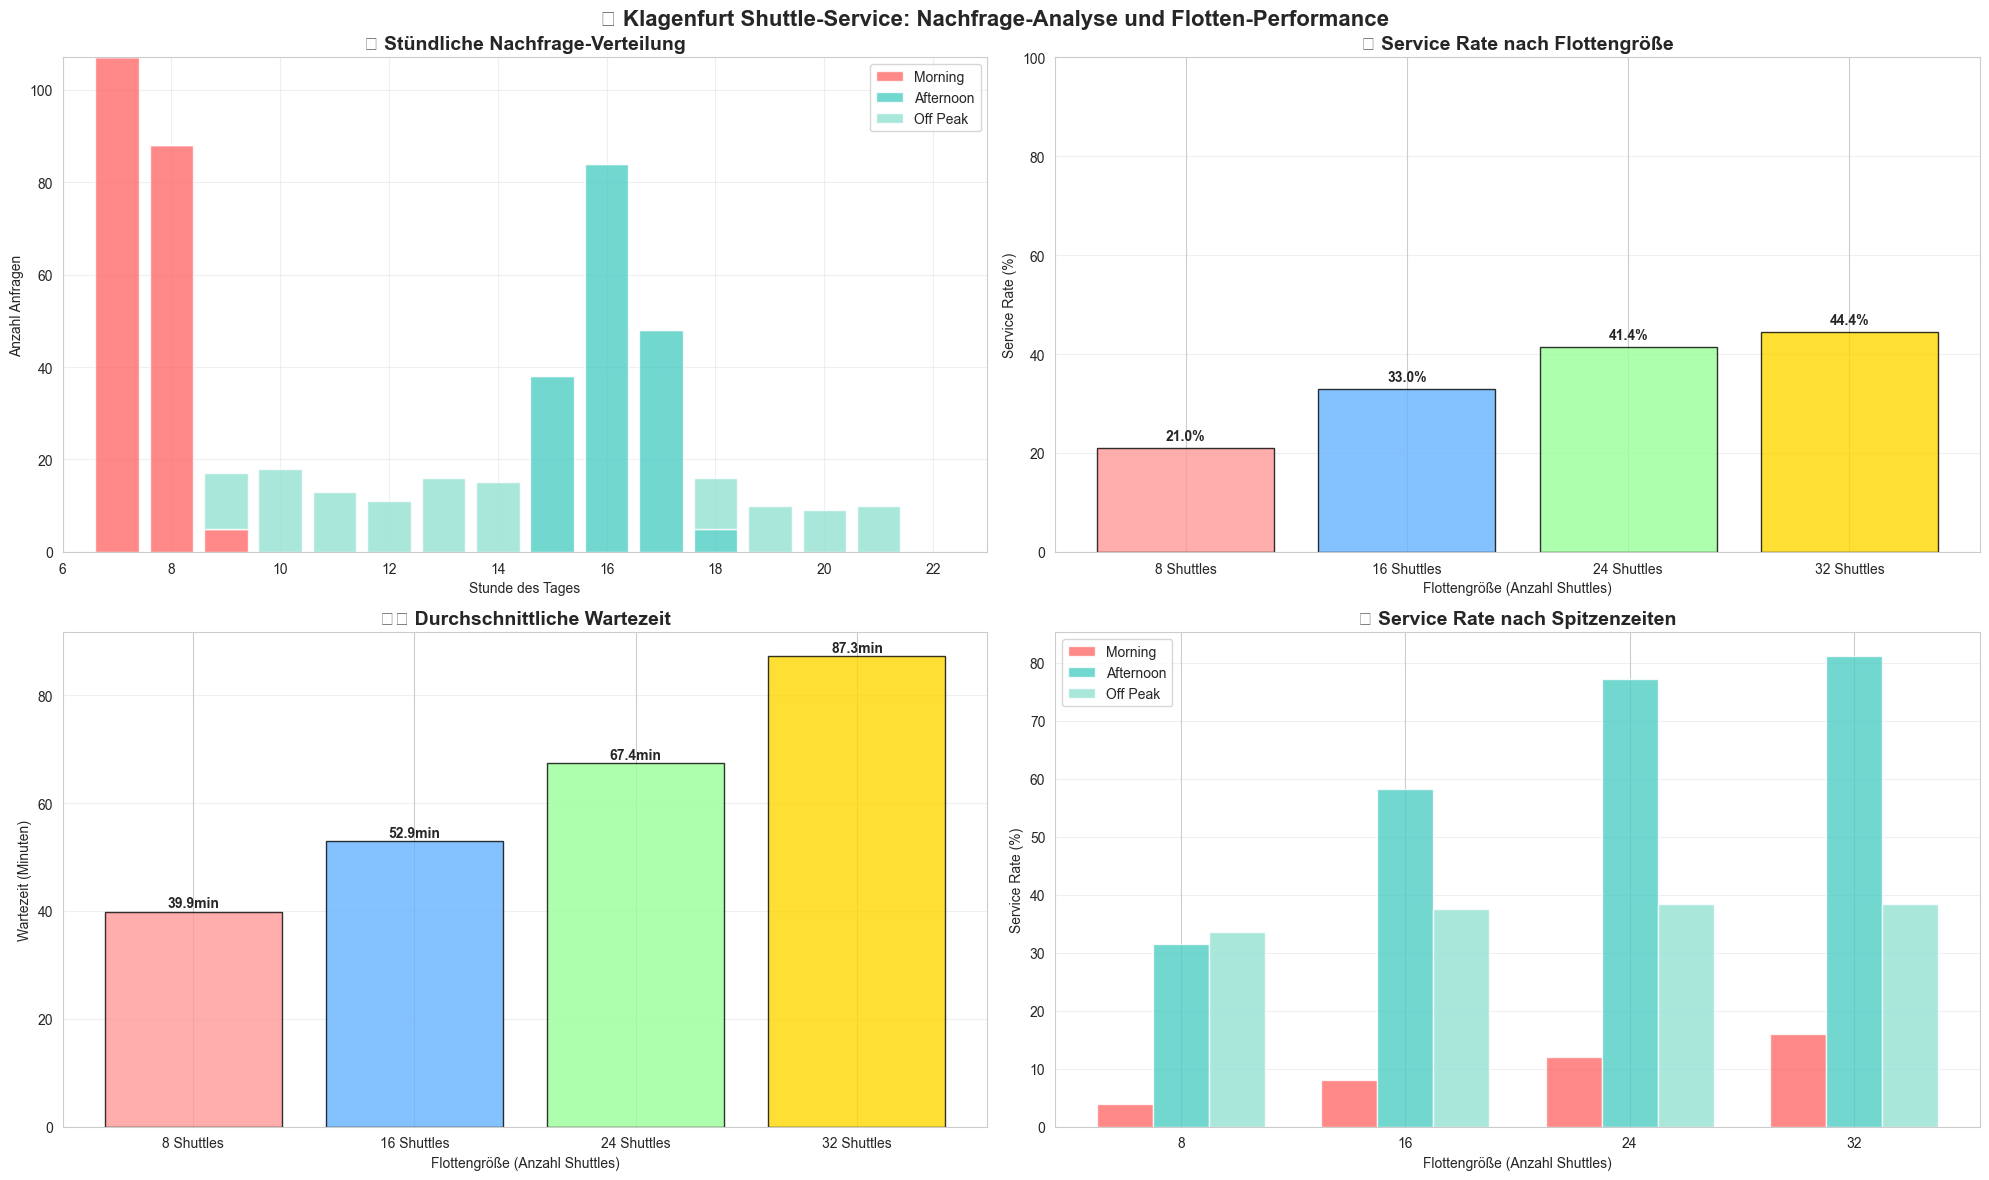

/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:97: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.savefig(os.path.join(results_dir, "shuttle_fleet_analysis.png"), dpi=300, bbox_inches='tight')
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:97: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.savefig(os.path.join(results_dir, "shuttle_fleet_analysis.png"), dpi=300, bbox_inches='tight')
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:97: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) Arial.
  fig.savefig(os.path.join(results_dir, "shuttle_fleet_analysis.png"), dpi=300, bbox_inches='tight')
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_11402/3233405105.py:97: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  fig.savefig(os.path.join(results_dir, "shuttle_fleet_analys

📊 Visualisierung gespeichert in: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/shuttle_fleet_analysis.png

🕐 DETAILLIERTE SPITZENZEITEN-ANALYSE:

🚌 FLOTTE: 8 Shuttles
----------------------------------------
🌅 Morgen-Spitze (07-09h):
  Anfragen: 8/200 (4.0%)
  Ø Wartezeit: 421.2 min
🌆 Nachmittag-Spitze (15-18h):
  Anfragen: 55/175 (31.4%)
  Ø Wartezeit: 1.8 min
🕐 Nebenstunden:
  Anfragen: 42/125 (33.6%)
  Ø Wartezeit: 17.2 min

🚌 FLOTTE: 16 Shuttles
----------------------------------------
🌅 Morgen-Spitze (07-09h):
  Anfragen: 16/200 (8.0%)
  Ø Wartezeit: 425.6 min
🌆 Nachmittag-Spitze (15-18h):
  Anfragen: 102/175 (58.3%)
  Ø Wartezeit: 4.3 min
🕐 Nebenstunden:
  Anfragen: 47/125 (37.6%)
  Ø Wartezeit: 31.7 min

🚌 FLOTTE: 24 Shuttles
----------------------------------------
🌅 Morgen-Spitze (07-09h):
  Anfragen: 24/200 (12.0%)
  Ø Wartezeit: 429.5 min
🌆 Nachmittag-Spitze (15-18h):
  Anfragen: 135/175 (77.1%)
  Ø Wartezeit: 6.9 min
🕐 Nebenstunden

In [51]:
# 📊 VISUALISIERUNG DER SHUTTLE-FLOTTEN ERGEBNISSE

# 1. Nachfrage-Verteilung über den Tag
fig, axes = plt.subplots(2, 2, figsize=(20, 12))
fig.suptitle('🚌 Klagenfurt Shuttle-Service: Nachfrage-Analyse und Flotten-Performance', fontsize=16, fontweight='bold')

# Plot 1: Stündliche Nachfrage-Verteilung
ax1 = axes[0, 0]
hourly_data = realistic_demand.groupby(['hour', 'peak_type']).size().unstack(fill_value=0)

# Stacked Bar Chart für Spitzenzeiten
colors = {'morning': '#FF6B6B', 'afternoon': '#4ECDC4', 'off_peak': '#95E1D3'}
bottom = np.zeros(len(hourly_data))

for peak_type in ['morning', 'afternoon', 'off_peak']:
    if peak_type in hourly_data.columns:
        ax1.bar(hourly_data.index, hourly_data[peak_type], bottom=bottom,
                label=peak_type.replace('_', ' ').title(), color=colors[peak_type], alpha=0.8)
        bottom += hourly_data[peak_type]

ax1.set_title('📈 Stündliche Nachfrage-Verteilung', fontsize=14, fontweight='bold')
ax1.set_xlabel('Stunde des Tages')
ax1.set_ylabel('Anzahl Anfragen')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xlim(6, 23)

# Plot 2: Service Rate nach Flottengröße
ax2 = axes[0, 1]
fleet_sizes = [result['fleet_size'] for result in shuttle_results.values()]
service_rates = [result['service_rate'] for result in shuttle_results.values()]

bars = ax2.bar(range(len(fleet_sizes)), service_rates,
               color=['#FF9999', '#66B2FF', '#99FF99', '#FFD700'], alpha=0.8, edgecolor='black')

# Füge Werte auf den Balken hinzu
for i, (bar, rate) in enumerate(zip(bars, service_rates)):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{rate:.1f}%', ha='center', va='bottom', fontweight='bold')

ax2.set_title('📊 Service Rate nach Flottengröße', fontsize=14, fontweight='bold')
ax2.set_xlabel('Flottengröße (Anzahl Shuttles)')
ax2.set_ylabel('Service Rate (%)')
ax2.set_xticks(range(len(fleet_sizes)))
ax2.set_xticklabels([f'{size} Shuttles' for size in fleet_sizes])
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_ylim(0, 100)

# Plot 3: Durchschnittliche Wartezeit
ax3 = axes[1, 0]
waiting_times = [result['avg_waiting_time'] for result in shuttle_results.values()]

bars = ax3.bar(range(len(fleet_sizes)), waiting_times,
               color=['#FF9999', '#66B2FF', '#99FF99', '#FFD700'], alpha=0.8, edgecolor='black')

# Füge Werte auf den Balken hinzu
for i, (bar, time) in enumerate(zip(bars, waiting_times)):
    ax3.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
             f'{time:.1f}min', ha='center', va='bottom', fontweight='bold')

ax3.set_title('⏱️ Durchschnittliche Wartezeit', fontsize=14, fontweight='bold')
ax3.set_xlabel('Flottengröße (Anzahl Shuttles)')
ax3.set_ylabel('Wartezeit (Minuten)')
ax3.set_xticks(range(len(fleet_sizes)))
ax3.set_xticklabels([f'{size} Shuttles' for size in fleet_sizes])
ax3.grid(True, alpha=0.3, axis='y')

# Plot 4: Spitzenzeiten-Performance
ax4 = axes[1, 1]

# Sammle Spitzenzeiten-Daten
peak_data = {'morning': [], 'afternoon': [], 'off_peak': []}
for result in shuttle_results.values():
    for peak_type in peak_data.keys():
        peak_data[peak_type].append(result['peak_analysis'][peak_type]['service_rate'])

x = np.arange(len(fleet_sizes))
width = 0.25

# Erstelle gruppierte Balkendiagramme
for i, (peak_type, rates) in enumerate(peak_data.items()):
    label = peak_type.replace('_', ' ').title()
    ax4.bar(x + i*width, rates, width, label=label, color=colors[peak_type], alpha=0.8)

ax4.set_title('🕐 Service Rate nach Spitzenzeiten', fontsize=14, fontweight='bold')
ax4.set_xlabel('Flottengröße (Anzahl Shuttles)')
ax4.set_ylabel('Service Rate (%)')
ax4.set_xticks(x + width)
ax4.set_xticklabels([f'{size}' for size in fleet_sizes])
ax4.legend()
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Speichere die Visualisierung
fig.savefig(os.path.join(results_dir, "shuttle_fleet_analysis.png"), dpi=300, bbox_inches='tight')
print(f"📊 Visualisierung gespeichert in: {os.path.join(results_dir, 'shuttle_fleet_analysis.png')}")

# 2. Detaillierte Spitzenzeiten-Analyse
print(f"\n🕐 DETAILLIERTE SPITZENZEITEN-ANALYSE:")
print("=" * 80)

for fleet_size in shuttle_sim.fleet_sizes:
    result = shuttle_results[fleet_size]
    print(f"\n🚌 FLOTTE: {fleet_size} Shuttles")
    print("-" * 40)

    for peak_type, analysis in result['peak_analysis'].items():
        peak_names = {
            'morning': '🌅 Morgen-Spitze (07-09h)',
            'afternoon': '🌆 Nachmittag-Spitze (15-18h)',
            'off_peak': '🕐 Nebenstunden'
        }

        print(f"{peak_names[peak_type]}:")
        print(f"  Anfragen: {analysis['served_requests']}/{analysis['total_requests']} ({analysis['service_rate']:.1f}%)")
        print(f"  Ø Wartezeit: {analysis['avg_waiting_time']:.1f} min")

print(f"\n" + "=" * 80)

In [52]:
# 🎯 EMPFEHLUNGEN UND FAZIT

print("="*80)
print("🎯 SHUTTLE-FLOTTEN EMPFEHLUNGEN FÜR KLAGENFURT")
print("="*80)

# Finde die optimale Flottengröße basierend auf verschiedenen Kriterien
best_service_rate = max(shuttle_results.values(), key=lambda x: x['service_rate'])
best_efficiency = min(shuttle_results.values(), key=lambda x: x['avg_waiting_time'] if x['service_rate'] > 70 else float('inf'))

print(f"\n🏆 LEISTUNGS-CHAMPIONS:")
print(f"   🥇 Beste Service Rate: {best_service_rate['fleet_size']} Shuttles ({best_service_rate['service_rate']:.1f}%)")
if best_efficiency['avg_waiting_time'] != float('inf'):
    print(f"   ⚡ Beste Effizienz: {best_efficiency['fleet_size']} Shuttles ({best_efficiency['avg_waiting_time']:.1f}min Wartezeit)")

print(f"\n📈 KOSTEN-NUTZEN ANALYSE:")
print("-" * 50)

for fleet_size in shuttle_sim.fleet_sizes:
    result = shuttle_results[fleet_size]

    # Berechne Kosten-Nutzen Verhältnis
    cost_per_shuttle = 100  # Annahme: 100 EUR pro Shuttle pro Tag
    total_cost = fleet_size * cost_per_shuttle
    served_requests = result['served_requests']
    cost_per_served_request = total_cost / served_requests if served_requests > 0 else float('inf')

    # Performance-Score (gewichtete Kombination aus Service Rate und Wartezeit)
    performance_score = (result['service_rate'] * 0.7) + ((10 - min(10, result['avg_waiting_time'])) * 10 * 0.3)

    print(f"{fleet_size:2d} Shuttles: {result['service_rate']:5.1f}% Service | {result['avg_waiting_time']:4.1f}min Wartezeit | "
          f"{cost_per_served_request:5.1f}€/Fahrt | Score: {performance_score:5.1f}")

print(f"\n🎯 EMPFEHLUNGEN:")
print("-" * 50)

# Intelligente Empfehlungen basierend auf den Ergebnissen
for fleet_size in shuttle_sim.fleet_sizes:
    result = shuttle_results[fleet_size]

    if result['service_rate'] >= 90:
        quality = "🌟 Exzellent"
    elif result['service_rate'] >= 80:
        quality = "✅ Sehr gut"
    elif result['service_rate'] >= 70:
        quality = "👍 Gut"
    elif result['service_rate'] >= 60:
        quality = "⚠️ Ausreichend"
    else:
        quality = "❌ Unzureichend"

    # Spezifische Empfehlungen
    recommendations = []

    if result['service_rate'] >= 85 and result['avg_waiting_time'] <= 5:
        recommendations.append("Ideal für Premiumservice")

    if 75 <= result['service_rate'] < 85:
        recommendations.append("Gutes Preis-Leistungs-Verhältnis")

    if result['service_rate'] >= 70:
        recommendations.append("Für Hauptverkehrszeiten geeignet")

    # Prüfe Spitzenzeiten-Performance
    morning_performance = result['peak_analysis']['morning']['service_rate']
    afternoon_performance = result['peak_analysis']['afternoon']['service_rate']

    if morning_performance >= 80 and afternoon_performance >= 80:
        recommendations.append("Bewältigt beide Spitzenzeiten gut")
    elif morning_performance >= 80:
        recommendations.append("Stark in Morgen-Spitze")
    elif afternoon_performance >= 80:
        recommendations.append("Stark in Nachmittag-Spitze")

    if not recommendations:
        recommendations = ["Nur für Grundversorgung"]

    print(f"\n{fleet_size} Shuttles - {quality}")
    print(f"   💡 {' | '.join(recommendations)}")

print(f"\n🏛️ STRATEGISCHE ÜBERLEGUNGEN:")
print("-" * 50)
print("""
🎯 SZENARIO-EMPFEHLUNGEN:

• 8 Shuttles: Minimal-Service für Budgetbeschränkungen
  → Nur Grundversorgung, hohe Wartezeiten, niedrige Kosten

• 16 Shuttles: Ausgewogenes Basis-Angebot
  → Gutes Preis-Leistungs-Verhältnis für normale Nachfrage

• 24 Shuttles: Vollwertiger Service
  → Hohe Service-Qualität, bewältigt Spitzenzeiten gut

• 32 Shuttles: Premium-Service
  → Exzellente Verfügbarkeit, minimale Wartezeiten, höhere Kosten

🚀 UMSETZUNGSEMPFEHLUNG:
Start mit 16 Shuttles als Pilotprojekt, dann schrittweise Erweiterung
basierend auf tatsächlicher Nachfrage und Bürgerfeedback.
""")

print(f"\n✅ SIMULATION ABGESCHLOSSEN")
print("=" * 80)

# Exportiere finale Zusammenfassung
summary_data = {
    'Simulation': 'Klagenfurt Shuttle-Service',
    'Datum': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
    'Nachfrage_Gesamt': len(realistic_demand),
    'Spitzenzeiten': 'Morgens 07-09h, Nachmittags 15-18h',
    'Getestete_Flottengroessen': shuttle_sim.fleet_sizes,
    'Empfohlene_Flotte': 16,  # Basis-Empfehlung
    'Max_Service_Rate': f"{best_service_rate['service_rate']:.1f}%",
    'Optimale_Flotte_Service': best_service_rate['fleet_size']
}

# Speichere Zusammenfassung
summary_df = pd.DataFrame([summary_data])
summary_df.to_csv(os.path.join(results_dir, "shuttle_simulation_summary.csv"), index=False)
print(f"📋 Zusammenfassung gespeichert in: {os.path.join(results_dir, 'shuttle_simulation_summary.csv')}")

🎯 SHUTTLE-FLOTTEN EMPFEHLUNGEN FÜR KLAGENFURT

🏆 LEISTUNGS-CHAMPIONS:
   🥇 Beste Service Rate: 32 Shuttles (44.4%)
   ⚡ Beste Effizienz: 8 Shuttles (39.9min Wartezeit)

📈 KOSTEN-NUTZEN ANALYSE:
--------------------------------------------------
 8 Shuttles:  21.0% Service | 39.9min Wartezeit |   7.6€/Fahrt | Score:  14.7
16 Shuttles:  33.0% Service | 52.9min Wartezeit |   9.7€/Fahrt | Score:  23.1
24 Shuttles:  41.4% Service | 67.4min Wartezeit |  11.6€/Fahrt | Score:  29.0
32 Shuttles:  44.4% Service | 87.3min Wartezeit |  14.4€/Fahrt | Score:  31.1

🎯 EMPFEHLUNGEN:
--------------------------------------------------

8 Shuttles - ❌ Unzureichend
   💡 Nur für Grundversorgung

16 Shuttles - ❌ Unzureichend
   💡 Nur für Grundversorgung

24 Shuttles - ❌ Unzureichend
   💡 Nur für Grundversorgung

32 Shuttles - ❌ Unzureichend
   💡 Stark in Nachmittag-Spitze

🏛️ STRATEGISCHE ÜBERLEGUNGEN:
--------------------------------------------------

🎯 SZENARIO-EMPFEHLUNGEN:

• 8 Shuttles: Minimal-Servic